# LLM + GP 因子挖掘：5 分钟 demo

**问题**：在相同数据、相同评估预算、相同门槛下，LLM、GP、随机搜索各自的贡献是多少？LLM+GP 是否真的有样本外（OOS）增量？

本 notebook 只读取已经生成的 artifacts，不重跑回测；按 **数据 → 候选 → S1 → 组合 → 消融/OOS** 走一遍。完整报告在 `项目报告/`。

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "artifacts").exists():
    ROOT = ROOT.parent
ART = ROOT / "artifacts"
print("project root:", ROOT)

project root: D:\quant\llm-gp-factor-lab


## 1. 数据与约束

PIT CSI300、2010–2026；2023–2026 的涨跌停/ST/停牌来自 zzshare 精确日线，并用 2020–2023 Dolt 重叠区间对账。

In [2]:
constraints = json.loads((ART / "stage10c" / "constraints_summary.json").read_text(encoding="utf-8"))
validation = json.loads((ART / "stage10c" / "constraints_validation.json").read_text(encoding="utf-8"))
rows = []
for board, item in validation["by_board"].items():
    rows.append({
        "board": board,
        "n_instruments": item["n_instruments"],
        "pre_close_match": item["mean_pre_close_match"],
        "at_limit_up_agreement": item["mean_at_limit_up_agreement"],
        "at_limit_down_agreement": item["mean_at_limit_down_agreement"],
        "is_st_agreement": item["mean_is_st_agreement"],
    })
display(pd.DataFrame(rows).set_index("board").round(4))
print(f"2023-2026 约束面板: {constraints['n_rows']:,} 行, {constraints['n_instruments']} 只, "
      f"涨停日 {constraints['n_limit_up_days']}, 跌停日 {constraints['n_limit_down_days']}")

,n_instruments,pre_close_match,at_limit_up_agreement,at_limit_down_agreement,is_st_agreement
board,,,,,
main_board,3,1.0,1.0000,1.0,1.0000
gem_20pct,2,1.0,0.9971,1.0,0.9986


2023-2026 约束面板: 244,200 行, 385 只, 涨停日 1916, 跌停日 574


## 2. 候选漏斗

Stage 5 的 LLM 候选、Stage 6 的 GP 进化、Stage 7 的相关性去重、Stage 8 的 S2 稳健性，最终进入 Stage 10C 的四组消融。

In [3]:
s5 = pd.read_parquet(ROOT / "data" / "mining" / "stage5_candidates_combined.parquet")
s7 = json.loads((ART / "stage7" / "summary.json").read_text(encoding="utf-8"))
s8 = pd.read_csv(ART / "stage8" / "s2_scorecard.csv")
funnel = pd.DataFrame([
    ["Stage 5 LLM 候选", len(s5), f"valid={int((s5.validation_status == 'valid').sum())}"],
    ["Stage 6 GP 评估", 2000, "18 generations"],
    ["Stage 7 去重后代表", s7["n_representatives"], f"{s7['n_candidates']} candidates / {s7['n_correlation_clusters']} clusters"],
    ["Stage 8 S2 pass", int((s8.s2_status == "pass").sum()), f"{len(s8)} candidates"],
    ["Stage 10C 下游", 119, "30/30/30/29 after coverage + |rho|>0.70 dedup"],
], columns=["stage", "n", "note"])
display(funnel.set_index("stage"))

,n,note
stage,,
Stage 5 LLM 候选,236,valid=230
Stage 6 GP 评估,2000,18 generations
Stage 7 去重后代表,11,55 candidates / 11 clusters
Stage 8 S2 pass,7,14 candidates
Stage 10C 下游,119,30/30/30/29 after coverage + |rho|>0.70 dedup


## 3. S1 与四组消融

四组使用相同的 2010–2016 S1 校准、2017–2018 搜索/选择、2023–2026 OOS。

In [4]:
summary = json.loads((ART / "stage10c" / "summary.json").read_text(encoding="utf-8"))
rows = []
for item in summary["ablation"]:
    rows.append({
        "group": item["label"],
        "S1 pass / n": f"{item['n_pass']} / {item['n_s1']}",
        "S1 pass rate": item["s1_pass_rate"],
        "OOS net excess": item["oos_excess_annual"],
        "OOS IR": item["oos_net_excess_ir"],
        "turnover": item["oos_turnover_annual"],
        "max drawdown": item["oos_max_drawdown"],
    })
table = pd.DataFrame(rows).set_index("group")
display(table.style.format({
    "S1 pass rate": "{:.1%}", "OOS net excess": "{:+.2%}", "OOS IR": "{:.2f}",
    "turnover": "{:.1f}x", "max drawdown": "{:.1%}",
}))
print("OOS: 2023-06-13 .. 2026-10-23 | benchmark annual: {:+.2%}".format(
    summary["ablation"][0]["oos_benchmark_annual"]))

,S1 pass / n,S1 pass rate,OOS net excess,OOS IR,turnover,max drawdown
group,,,,,,
A random search,4 / 30,13.3%,-5.22%,-0.57,18.7x,-30.1%
B GP-only,6 / 30,20.0%,-5.16%,-0.53,18.3x,-27.3%
C LLM-only,14 / 30,46.7%,-9.14%,-0.87,19.8x,-31.7%
D LLM+GP,6 / 29,20.7%,-4.43%,-0.38,19.4x,-35.5%


OOS: 2023-06-13 .. 2026-10-23 | benchmark annual: +1.90%


## 4. OOS 累计净超额

曲线从 2023-06 开始，四组都跑输 CSI300；2025-09 之后回撤扩大。

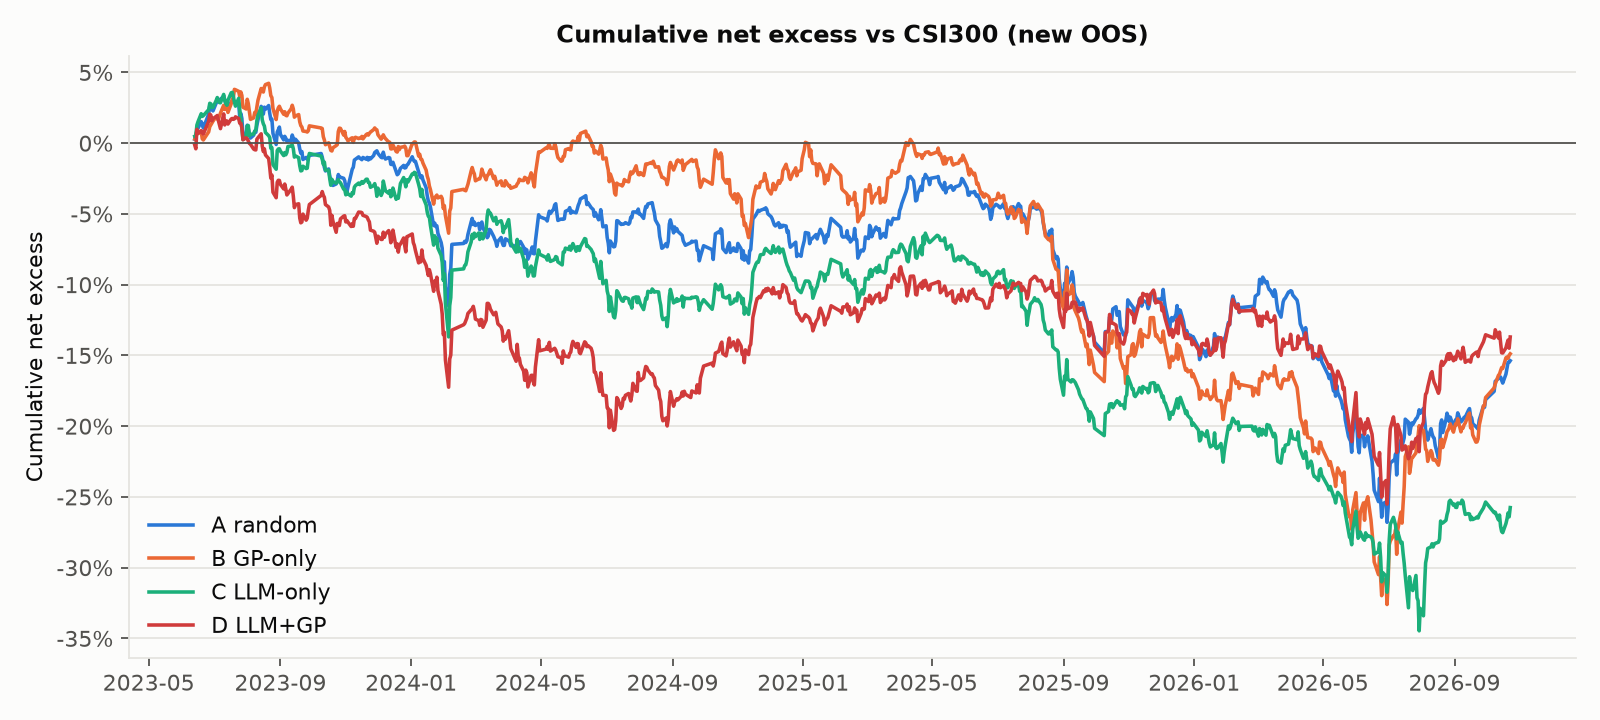

In [5]:
display(Image(filename=str(ROOT / "项目报告" / "assets" / "stage10c_oos_cumulative.png")))

## 5. 一个数据质量发现

Dolt 的 `final_a_stock_limit` 对创业板/科创板（300/688）记录的是 10% 限价，而实际是 20%。在 2020–2023 OOS 中，它标记的 102 个涨停日 + 42 个跌停日，按 20% 复核**全部是假阳性**。Stage 10C 改用 zzshare 精确限价修正。

In [6]:
print("Dolt 300/688 假涨跌停标记: 102 涨停 + 42 跌停 = 144")
print("修正后 Stage 10C 面板 at_limit_up/down:", constraints["n_limit_up_days"], "/", constraints["n_limit_down_days"])
print("主板 at-limit 标记对账一致率:", validation["by_board"]["main_board"]["mean_at_limit_up_agreement"])

Dolt 300/688 假涨跌停标记: 102 涨停 + 42 跌停 = 144
修正后 Stage 10C 面板 at_limit_up/down: 1916 / 574
主板 at-limit 标记对账一致率: 1.0


## 6. 结论

1. **四组在 2023–2026 全部负净超额**：A -5.22%、B -5.16%、C -9.14%、D -4.43%。
2. **LLM+GP 没有可证明的 OOS 增量**：D−B = +0.72pp，bootstrap 95% CI [-9.40%, +13.04%]。
3. **S1 通过率 ≠ OOS 净收益**：C 的 pass rate 最高（46.7%），OOS 却最差。
4. **10B 的 A +3.84% 没有复现**；10B 自身 bootstrap CI 也跨 0。
5. 约束修正去掉了 144 个假标记，但没有让任何一组转正。

> 这是 2023–2026 的第一次 OOS，但项目已评估过 2020–2023 两轮；跨窗口多重比较仍然存在。完整版见 `项目报告/Stage10C_新OOS_2023-2026_项目报告.md`。